# Лабораторна робота №11
**«Теорія розпізнавання образів та класифікації в системах ШІ»**

* **Тема:** Нейромережеві методи класифікації. Персептрон і багатошаровий персептрон
* **Команда:** банк
* **Склад команди:** Сотниченко Артем Валентинович , Вірченко Богдан, Тринько Микита
* **Група:** КН23002б
* **Тема проєкту:** AI-система прогнозування відтоку клієнтів банку, банківський скоринг

**Мета роботи:** набути практичних навичок побудови нейромережевого класифікатора, дослідити вплив архітектури та кількості епох на перенавчання, порівняти результати з найкращим класичним методом із попередніх робіт

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import time

from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme(style="whitegrid")

# Завантаження даних
TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print(f"Дані завантажено. Тренувальна вибірка: {X_train.shape}, Тестова: {X_test.shape}")

Дані завантажено. Тренувальна вибірка: (8000, 9), Тестова: (2000, 9)


## Завдання 1. Побудова базового класифікатора MLPClassifier
Нейронні мережі критично залежать від масштабу ознак. Оскільки наші дані вже були стандартизовані під час другої лабораторної роботи, ми можемо одразу застосувати базовий багатошаровий персептрон з одним прихованим шаром на 100 нейронів за замовчуванням

Базовий MLP - Accuracy: 0.8665, F1: 0.5948


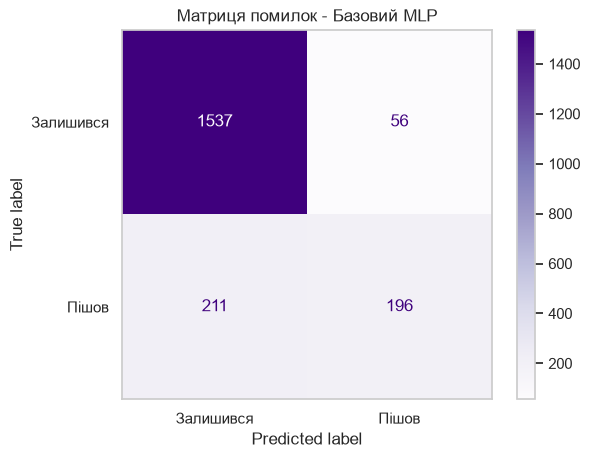

In [2]:
# Базова нейронна мережа
mlp_base = MLPClassifier(random_state=RANDOM_STATE, max_iter=300)
mlp_base.fit(X_train, y_train)

y_pred_base = mlp_base.predict(X_test)
f1_base = f1_score(y_test, y_pred_base)
acc_base = accuracy_score(y_test, y_pred_base)

print(f"Базовий MLP - Accuracy: {acc_base:.4f}, F1: {f1_base:.4f}")

cm = confusion_matrix(y_test, y_pred_base)
ConfusionMatrixDisplay(cm, display_labels=["Залишився", "Пішов"]).plot(cmap="Purples")
plt.title("Матриця помилок - Базовий MLP")
plt.grid(False)
plt.show()

## Завдання 2. Дослідження впливу архітектури мережі
Перевіримо, як кількість прихованих шарів та кількість нейронів у них впливає на здатність мережі виявляти закономірності. Протестуємо неглибокі та глибокі архітектури

,Train Accuracy,Test Accuracy,Train F1,Test F1
Архітектура,,,,
"(10,)",0.8598,0.8600,0.5727,0.5770
"(50,)",0.8685,0.8650,0.6072,0.5982
"(100,)",0.8715,0.8665,0.6100,0.5948
"(50, 25)",0.8820,0.8595,0.6493,0.5874
"(100, 50, 25)",0.9434,0.8085,0.8592,0.5289
"(10, 10, 10, 10)",0.8639,0.8610,0.5787,0.5697


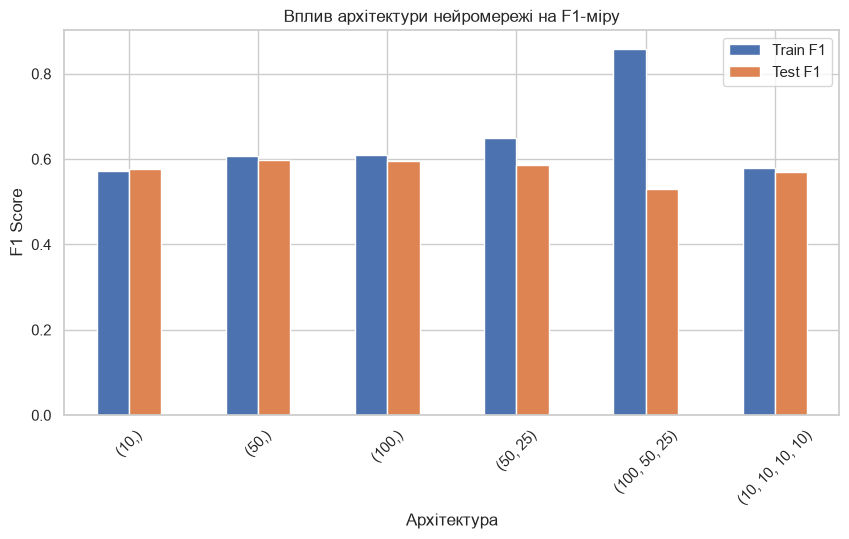

In [3]:
architectures = [
    (10,),              # Один малий шар
    (50,),              # Один середній шар
    (100,),             # Один великий шар (базовий)
    (50, 25),           # Два шари (звуження)
    (100, 50, 25),      # Три шари (глибока мережа)
    (10, 10, 10, 10)    # Чотири малі шари
]

arch_results = []

for arch in architectures:
    mlp = MLPClassifier(hidden_layer_sizes=arch, max_iter=300, random_state=RANDOM_STATE)
    mlp.fit(X_train, y_train)
    
    arch_results.append({
        "Архітектура": str(arch),
        "Train Accuracy": accuracy_score(y_train, mlp.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, mlp.predict(X_test)),
        "Train F1": f1_score(y_train, mlp.predict(X_train)),
        "Test F1": f1_score(y_test, mlp.predict(X_test))
    })

arch_df = pd.DataFrame(arch_results).set_index("Архітектура")
display(arch_df.round(4))

arch_df[["Train F1", "Test F1"]].plot(kind="bar", figsize=(10, 5), color=["#4C72B0", "#DD8452"])
plt.title("Вплив архітектури нейромережі на F1-міру")
plt.ylabel("F1 Score")
plt.xticks(rotation=45)
plt.show()

## Завдання 3. Вплив кількості епох на перенавчання 
Щоб побачити, як мережа навчається з часом, ми навчаємо її по одній епосі за допомогою partial_fit і після кожної епохи фіксуємо функцію втрат та F1 на навчальній і валідаційній вибірках. Валідаційна вибірка становить 20 відсотків тренувальної, а тестова в цьому завданні не використовується. Момент, коли validation loss починає зростати при продовженні падіння train loss, вказує на початок перенавчання

Мінімум validation loss досягається на епосі 21: 0.3446
Train loss на епосі 21: 0.3152, на епосі 200: 0.1715
Validation loss на епосі 200: 0.5404
Train F1 на епосі 200: 0.8185, Validation F1: 0.5413


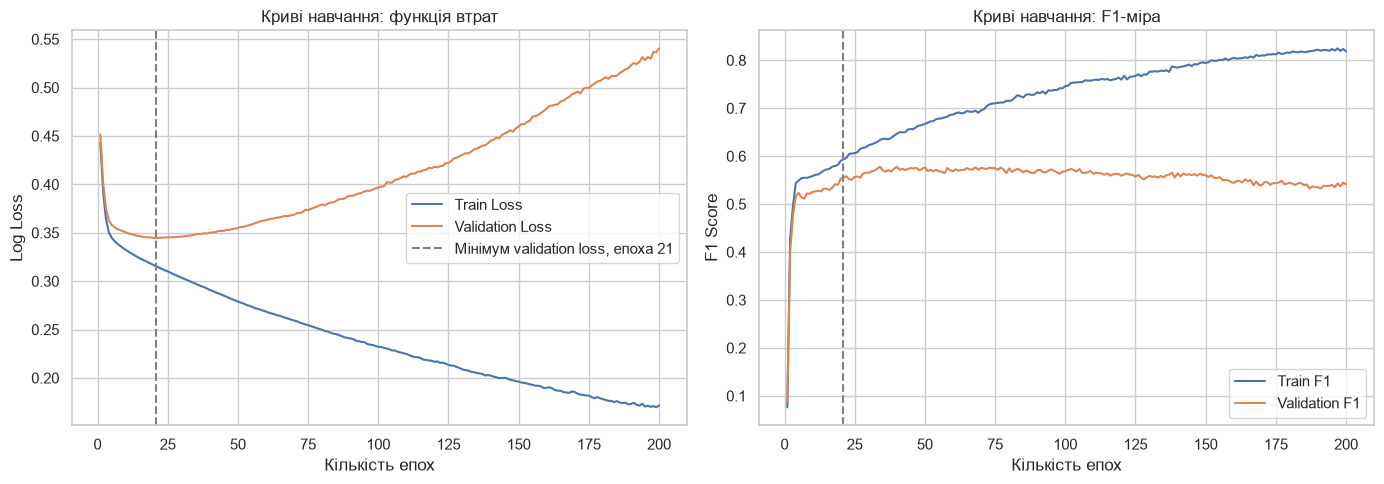

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss

# Валідаційна вибірка виділяється з тренувальної, тестова лишається недоторканою
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

n_epochs = 200
classes = np.unique(y_train)

# Глибока мережа, яка в завданні 2 перенавчалася найсильніше
mlp_curve = MLPClassifier(hidden_layer_sizes=(100, 50, 25), random_state=RANDOM_STATE)

history = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": []}

# partial_fit виконує рівно одну епоху за виклик
for epoch in range(n_epochs):
    mlp_curve.partial_fit(X_tr, y_tr, classes=classes)

    history["train_loss"].append(log_loss(y_tr, mlp_curve.predict_proba(X_tr)))
    history["val_loss"].append(log_loss(y_val, mlp_curve.predict_proba(X_val)))
    history["train_f1"].append(f1_score(y_tr, mlp_curve.predict(X_tr)))
    history["val_f1"].append(f1_score(y_val, mlp_curve.predict(X_val)))

epochs_axis = np.arange(1, n_epochs + 1)
best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"Мінімум validation loss досягається на епосі {best_epoch}: {min(history['val_loss']):.4f}")
print(f"Train loss на епосі {best_epoch}: {history['train_loss'][best_epoch - 1]:.4f}, на епосі {n_epochs}: {history['train_loss'][-1]:.4f}")
print(f"Validation loss на епосі {n_epochs}: {history['val_loss'][-1]:.4f}")
print(f"Train F1 на епосі {n_epochs}: {history['train_f1'][-1]:.4f}, Validation F1: {history['val_f1'][-1]:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Графік функції втрат
ax1.plot(epochs_axis, history["train_loss"], color="#4C72B0", label="Train Loss")
ax1.plot(epochs_axis, history["val_loss"], color="#DD8452", label="Validation Loss")
ax1.axvline(best_epoch, color="gray", linestyle="--", label=f"Мінімум validation loss, епоха {best_epoch}")
ax1.set_xlabel("Кількість епох")
ax1.set_ylabel("Log Loss")
ax1.set_title("Криві навчання: функція втрат")
ax1.legend()

# Графік F1
ax2.plot(epochs_axis, history["train_f1"], color="#4C72B0", label="Train F1")
ax2.plot(epochs_axis, history["val_f1"], color="#DD8452", label="Validation F1")
ax2.axvline(best_epoch, color="gray", linestyle="--")
ax2.set_xlabel("Кількість епох")
ax2.set_ylabel("F1 Score")
ax2.set_title("Криві навчання: F1-міра")
ax2.legend()

plt.tight_layout()
plt.show()

## Завдання 4. Порівняння з найкращим класичним методом
Порівняємо найкращу за Test F1 нейронну мережу із завдання 2 із найкращими ансамблевими моделями з попередніх робіт: випадковим лісом із лабораторної №9 та градієнтним бустингом із лабораторної №10, який показав найвищий F1

In [5]:
from sklearn.ensemble import GradientBoostingClassifier

# Найкраща архітектура за Test F1 із завдання 2
best_arch = architectures[int(np.argmax(arch_df["Test F1"].values))]
print(f"Найкраща архітектура за Test F1: {best_arch}")

# Нейронна мережа
best_mlp = MLPClassifier(hidden_layer_sizes=best_arch, max_iter=300, random_state=RANDOM_STATE)
start = time.perf_counter()
best_mlp.fit(X_train, y_train)
time_mlp = time.perf_counter() - start
pred_mlp = best_mlp.predict(X_test)

# Випадковий ліс із лаб 9
best_rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
start = time.perf_counter()
best_rf.fit(X_train, y_train)
time_rf = time.perf_counter() - start
pred_rf = best_rf.predict(X_test)

# Градієнтний бустинг із лаб 10, найкращий класичний метод за F1
best_gb = GradientBoostingClassifier(learning_rate=0.1, n_estimators=100, random_state=RANDOM_STATE)
start = time.perf_counter()
best_gb.fit(X_train, y_train)
time_gb = time.perf_counter() - start
pred_gb = best_gb.predict(X_test)

comp_df = pd.DataFrame({
    "Нейронна мережа (MLP)": {"Accuracy (Test)": accuracy_score(y_test, pred_mlp), "F1 (Test)": f1_score(y_test, pred_mlp), "Час навчання (с)": time_mlp},
    "Випадковий ліс (RF)": {"Accuracy (Test)": accuracy_score(y_test, pred_rf), "F1 (Test)": f1_score(y_test, pred_rf), "Час навчання (с)": time_rf},
    "Градієнтний бустинг (GB)": {"Accuracy (Test)": accuracy_score(y_test, pred_gb), "F1 (Test)": f1_score(y_test, pred_gb), "Час навчання (с)": time_gb}
}).T

display(comp_df.round(4))

Найкраща архітектура за Test F1: (50,)


,Accuracy (Test),F1 (Test),Час навчання (с)
Нейронна мережа (MLP),0.8650,0.5982,4.3429
Випадковий ліс (RF),0.8545,0.5584,0.6318
Градієнтний бустинг (GB),0.8695,0.6015,0.7707


## Загальні висновки та відповіді на контрольні питання

**Висновки за результатами дослідження:** 

Базовий MLP з одним прихованим шаром на 100 нейронів показав Accuracy 0.8665 і F1 0.5948. Дослідження архітектури показало, що збільшення кількості шарів і нейронів не покращує результат на тестовій вибірці. Найкращий Test F1 мала проста мережа з одним шаром на 50 нейронів, 0.5982, далі йдуть 100 нейронів з 0.5948 та 50, 25 з 0.5874. Глибока мережа 100, 50, 25 найсильніше запамятала тренувальну вибірку: Train Accuracy 0.9434 і Train F1 0.8592 проти Test Accuracy 0.8085 і Test F1 0.5289. Різниці між простими архітектурами невеликі, а експеримент виконано з одним значенням random_state, тому їх слід оцінювати обережно
Криві навчання для мережі 100, 50, 25 чітко показали перенавчання. Validation loss досягає мінімуму 0.3446 на 21 епосі, а далі зростає до 0.5404 на 200 епосі, тоді як Train loss продовжує падати з 0.3152 до 0.1715. Train F1 на 200 епосі становить 0.8185, а Validation F1 лише 0.5413. Validation F1 за графіком тримається близько 0.57 приблизно між 30 та 75 епохами, а потім повільно знижується. Це вказує на потребу в ранній зупинці приблизно на 20–50 епосі
Порівняння на тестовій вибірці: нейромережа 50 дала F1 0.5982 і Accuracy 0.8650, випадковий ліс 0.5584 і 0.8545, градієнтний бустинг 0.6015 і 0.8695. Нейромережа перевершує ліс за F1 на 0.0398, але від градієнтного бустингу відстає лише на 0.0033, що в межах випадкових коливань. Водночас вона навчається значно довше: 4.34 с проти 0.79 с у бустингу, тобто приблизно у 5.5 раза, і 0.69 с у лісу
Для даних команди найдоцільнішим методом є градієнтний бустинг з темпом навчання 0.1 та 100 ітераціями: він має найвищі F1 і Accuracy, навчається швидко і не потребує підбору архітектури та кількості епох. Нейромережа не дає виграшу, потребує ранньої зупинки і є чорною скринькою, тому для табличних даних цього проєкту вона не виправдана. Якщо потрібна інтерпретованість, краще використовувати одиночне дерево або логістичну регресію. Слід памятати, що гіперпараметри обиралися за тестовою вибіркою, а часи навчання виміряно один раз, тому для остаточного вибору потрібна крос-валідація

**Відповіді на питання для самоконтролю:**
1. Вихід одного персептрона обчислюється шляхом додавання зсуву до зваженої суми вхідних сигналів, після чого отримане значення пропускається через нелінійну функцію активації
2. Один персептрон може будувати лише пряму лінійну розділову межу, тому він не здатний вирішити задачу XOR, де класи розташовані по діагоналях і їх неможливо розділити однією лінією
3. Сигмоїда стискає значення в діапазон від нуля до одиниці, гіперболічний тангенс стискає від мінус одиниці до одиниці і є центрованим, ReLU повертає саме значення якщо воно додатне і нуль якщо відємне, що робить її дуже швидкою та захищає від згасання градієнта
4. Нелінійна функція активації є обовязковою, оскільки без неї будь-яка кількість шарів математично згорнеться в одну звичайну лінійну регресію і мережа втратить здатність моделювати складні залежності
5. Багатошаровий персептрон складається з вхідного шару кількість нейронів дорівнює кількості ознак, одного або кількох прихованих шарів та вихідного шару кількість нейронів залежить від кількості класів
6. Алгоритм зворотного поширення похибки спочатку робить прямий прохід для обчислення передбачення і похибки, а потім рухається у зворотному напрямку від виходу до входу, обчислюючи градієнти за правилом ланцюжка похідних для коригування ваг кожного шару
7. Епоха навчання це один повний прохід алгоритму через усю навчальну вибірку, надто велика кількість епох змушує мережу підлаштовуватися під статистичний шум і призводить до сильного перенавчання
8. Дерева рішень та логістична регресія є легко інтерпретованими моделями, де можна оцінити важливість кожної ознаки або прочитати правила, тоді як нейронна мережа працює як чорна скринька, і пояснити фізичний зміст її багатошарових ваг практично неможливо